In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../Resources/Revised Final Dataset.csv')
df['Month_Year'] = pd.to_datetime(df['Month_Year'], errors='coerce')
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health,Month_Year
0,Rural,103.9,101.9,103.1,105.5,104.0,2013-01-01
1,Urban,102.3,102.9,101.8,105.4,104.1,2013-01-01
2,Rural+Urban,103.2,102.2,102.7,105.5,104.0,2013-01-01
3,Rural,104.0,102.4,103.1,106.2,104.4,2013-02-01
4,Urban,103.1,104.9,102.3,105.7,104.7,2013-02-01


In [3]:
df.set_index('Month_Year', inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 453 entries, 2013-01-01 to 2025-07-01
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sector          453 non-null    object 
 1   Fruits          453 non-null    float64
 2   Vegetables      453 non-null    float64
 3   Spices          453 non-null    float64
 4   Fuel and light  453 non-null    float64
 5   Health          453 non-null    float64
dtypes: float64(5), object(1)
memory usage: 24.8+ KB


In [5]:
col_order = ['Sector', 'Fruits', 'Vegetables', 'Spices', 'Fuel and light', 'Health']
df = df[col_order]

In [6]:
df.head()

,Sector,Fruits,Vegetables,Spices,Fuel and light,Health
Month_Year,,,,,,
2013-01-01,Rural,103.9,101.9,103.1,105.5,104.0
2013-01-01,Urban,102.3,102.9,101.8,105.4,104.1
2013-01-01,Rural+Urban,103.2,102.2,102.7,105.5,104.0
2013-02-01,Rural,104.0,102.4,103.1,106.2,104.4
2013-02-01,Urban,103.1,104.9,102.3,105.7,104.7


In [7]:
df = df[df['Sector']=='Urban'].copy()
df = df.asfreq('MS')

In [8]:
df.index.min(), df.index.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2025-07-01 00:00:00'))

In [9]:
pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', length=151, freq='MS')

In [10]:
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='MS')

In [11]:
df.index

DatetimeIndex(['2013-01-01', '2013-02-01', '2013-03-01', '2013-04-01',
               '2013-05-01', '2013-06-01', '2013-07-01', '2013-08-01',
               '2013-09-01', '2013-10-01',
               ...
               '2024-10-01', '2024-11-01', '2024-12-01', '2025-01-01',
               '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01',
               '2025-06-01', '2025-07-01'],
              dtype='datetime64[ns]', name='Month_Year', length=151, freq='MS')

In [12]:
df.isna().sum()

Sector            0
Fruits            0
Vegetables        0
Spices            0
Fuel and light    0
Health            0
dtype: int64

In [13]:
df[df['Spices'].isna()]['Spices']
df['Spices'].interpolate().loc['2019-03-01':'2019-05-01']

Month_Year
2019-03-01    140.7
2019-04-01    140.4
2019-05-01    141.0
Freq: MS, Name: Spices, dtype: float64

In [14]:
df['Spices'] = df['Spices'].interpolate()
df['Spices'].isna().sum()

0

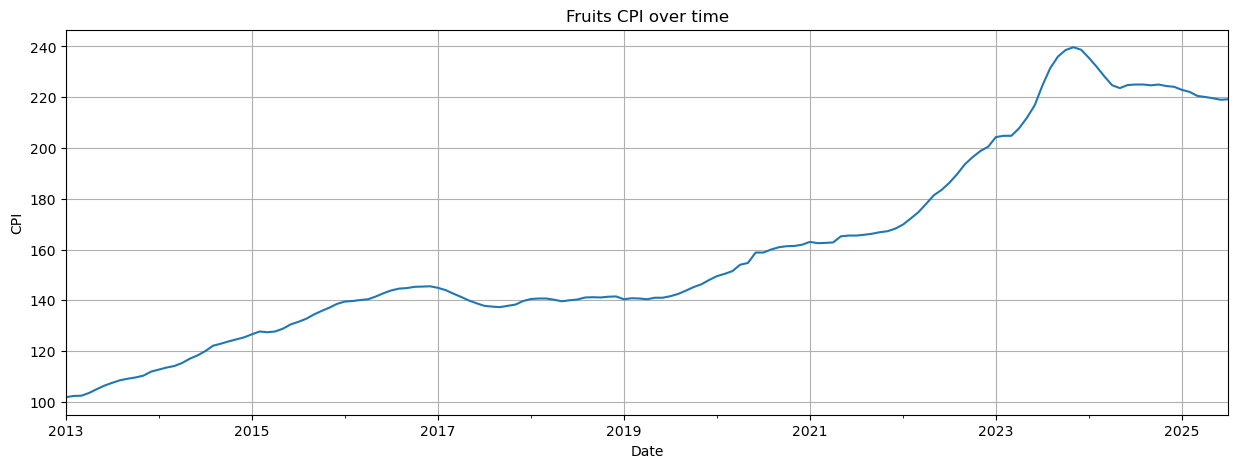

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
df['Spices'].plot()
plt.title('Fruits CPI over time')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.grid(True)
plt.show()

In [16]:
from statsmodels.tsa.seasonal import STL
stl = STL(df['Spices'], period=12)
result = stl.fit()

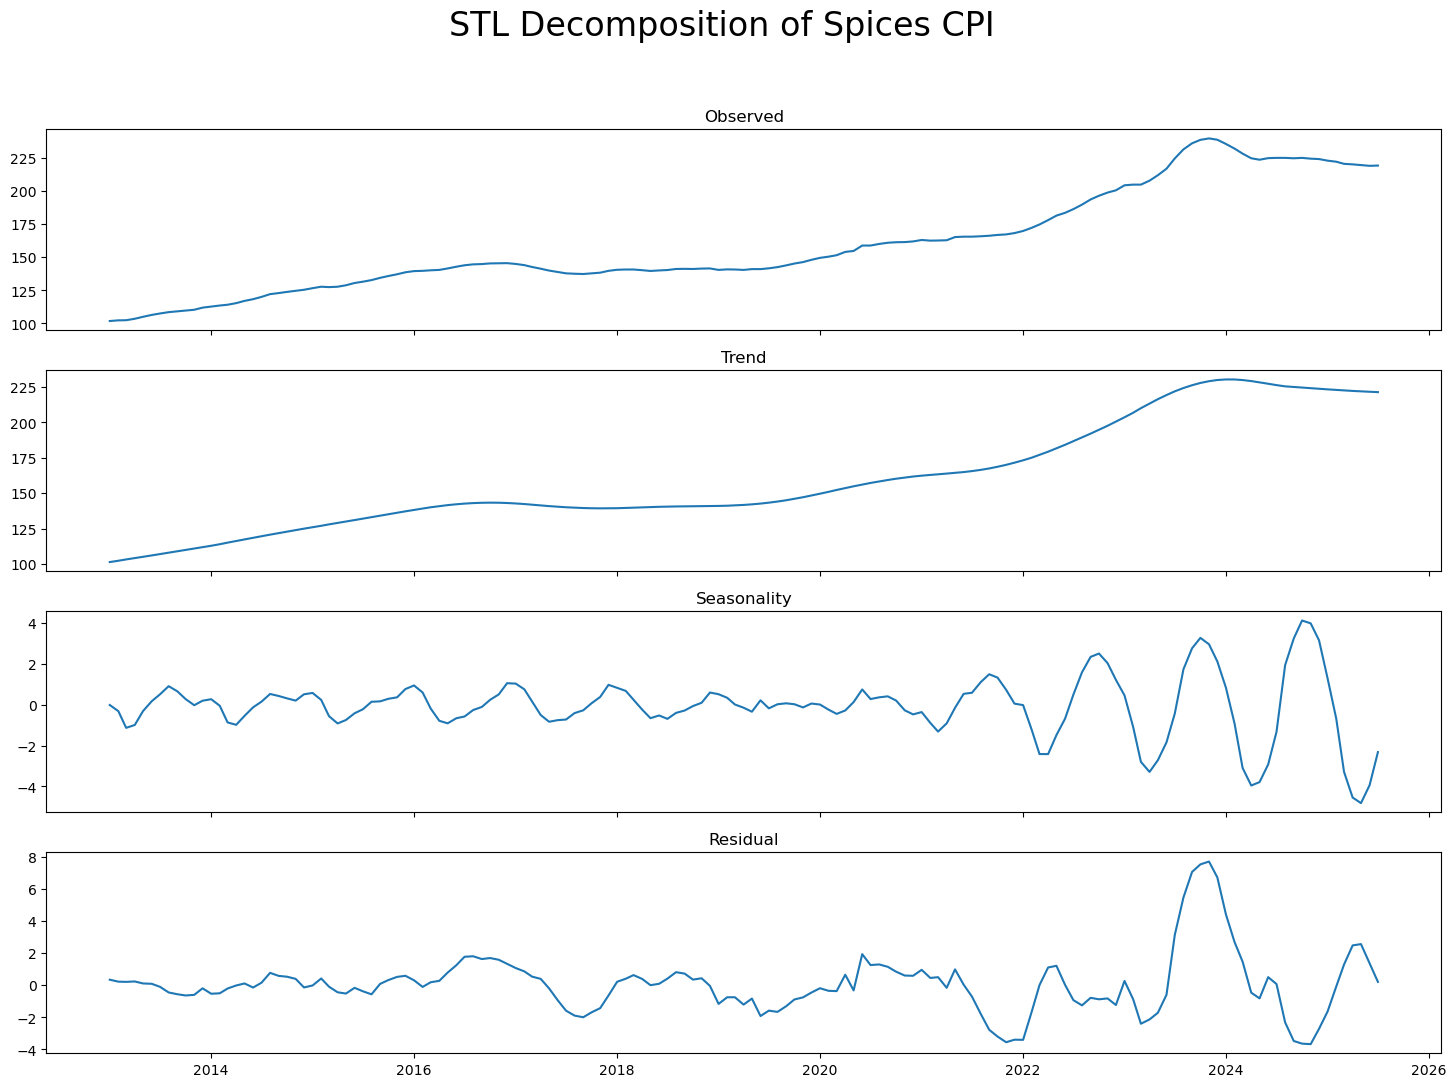

In [17]:
fig, axs = plt.subplots(4, 1, figsize=(18,12), sharex=True)

axs[0].plot(df.index, df['Spices'], label='Observed')
axs[0].set_title('Observed')

axs[1].plot(df.index, result.trend, label='Trend')
axs[1].set_title('Trend')

axs[2].plot(df.index, result.seasonal, label='Seasonality')
axs[2].set_title('Seasonality')

axs[3].plot(df.index, result.resid, label='Residual')
axs[3].set_title('Residual')

plt.suptitle('STL Decomposition of Spices CPI', fontsize=24)
plt.show()

In [18]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Spices'])
adf_result

(-0.6265735855003969,
 0.864863729288979,
 12,
 138,
 {'1%': -3.47864788917503,
  '5%': -2.882721765644168,
  '10%': -2.578065326612056},
 388.307033120176)

In [19]:
adf_result[0]

-0.6265735855003969

In [20]:
adf_result[1]

0.864863729288979

In [21]:
#cannot reject null hypothesis as 0.92428 > 0.05

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

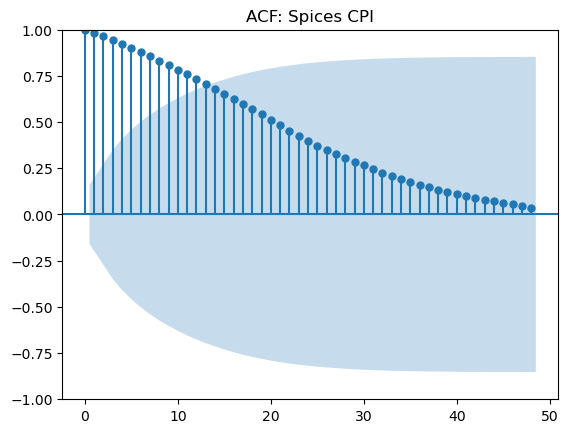

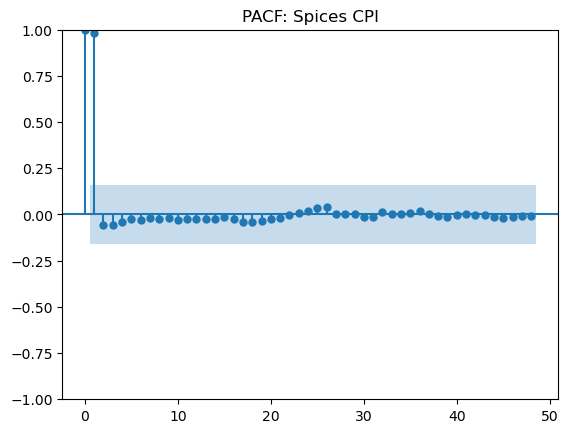

In [23]:
plot_acf(df['Spices'], lags=48)
plt.title('ACF: Spices CPI')
plt.show()

plot_pacf(df['Spices'], lags=48)
plt.title('PACF: Spices CPI')
plt.show()

In [24]:
# AR from PACF: sharp drop is from lag 1
# MA from ACF: lags 1 to 8 are significant 

In [25]:
test_size = 12 
train = df['Spices'].iloc[0:-test_size]
test = df['Spices'].iloc[-test_size:]

In [26]:
from statsmodels.tsa.arima.model import ARIMA

In [27]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                           Spices   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -192.844
Date:                          Sun, 22 Nov 2026   AIC                            391.688
Time:                                  15:33:05   BIC                            400.173
Sample:                              01-01-2013   HQIC                           395.135
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1678      0.056     -2.998      0.003      -0.278      -0.058
ma.S.L12      -0.9970      4.784     -0.208      0.835     -10.374       8.380
sigma2         1.0156      4.819      0.211      0.833      -8.429      10.460
===================================================================================
Ljung-Box (L1) (Q):                   0.06   Jarque-Bera (JB):                21.66
Prob(Q):                              0.81   Prob(JB):                         0.00
Heteroskedasticity (H):              10.37   Skew:                            -0.12
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.03
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

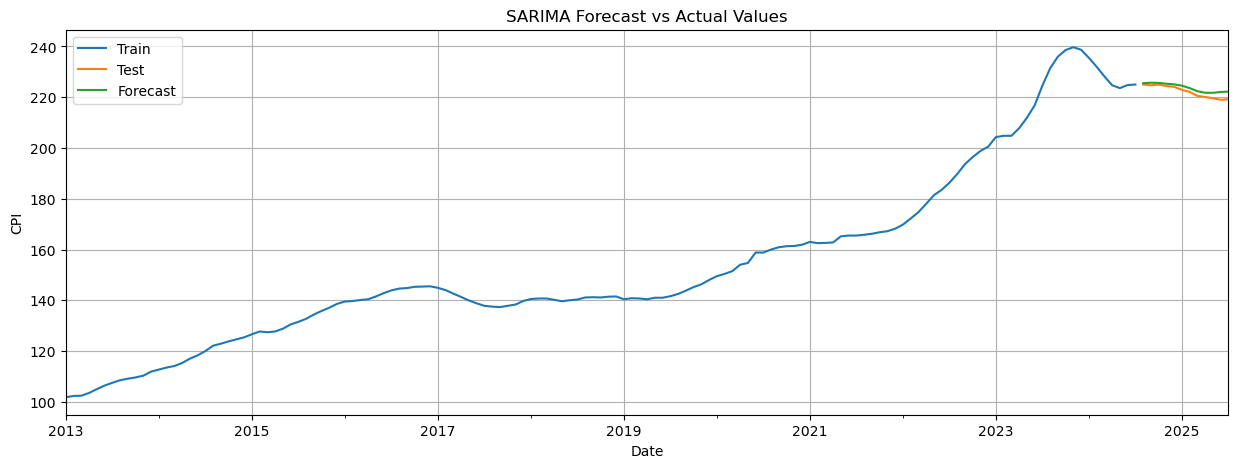

In [28]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

1.7766911922349973

In [30]:
s = 12

p_values = [0, 1, 2]
d_values = [1]
q_values = [0, 1, 2]

P_values = [0, 1, 2]
D_values = [1]
Q_values = [0, 1, 2]

In [31]:
param_grid = [((p, d, q), (P, D, Q, s))
 for p in p_values
 for d in d_values
 for q in q_values
 for P in P_values
 for D in D_values
 for Q in Q_values]

len(param_grid)

81

In [32]:
from sklearn.model_selection import TimeSeriesSplit

In [33]:
X = df['Spices']
tscv = TimeSeriesSplit(n_splits=3, test_size=12)
tscv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=12)

In [34]:
len(list(tscv.split(X)))

3

In [35]:
list(tscv.split(X))

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]),
  array([115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126])),
 (array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,

In [36]:
from tqdm import tqdm
import numpy as np

metrics = []

for order, seasonal_order in tqdm(param_grid):
    split_rmse = []

    for train_idx, test_idx in tscv.split(X):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        model = ARIMA(X_train, order=order, seasonal_order=seasonal_order)
        results = model.fit()

        X_pred = results.forecast(steps=len(X_test))
        rmse = np.sqrt(mean_squared_error(X_test, X_pred))
        split_rmse.append(rmse)

    mean_rmse = np.mean(split_rmse)
    std_rmse = np.std(split_rmse)

    metrics.append(
        {'order': order,
         'seasonal_order': seasonal_order,
         'rmse_mean': mean_rmse,
         'rmse_std': std_rmse}
    )

  0%|          | 0/81 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


 33%|███▎      | 27/81 [01:06<02:13,  2.48s/it]

 33%|███▎      | 27/81 [01:20<02:13,  2.48s/it]

... (26 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


100%|██████████| 81/81 [04:10<00:00,  3.09s/it]

In [37]:
metrics_df = pd.DataFrame(metrics)
metrics_df

,order,seasonal_order,rmse_mean,rmse_std
0,"(0, 1, 0)","(0, 1, 0, 12)",13.185481,3.536403
1,"(0, 1, 0)","(0, 1, 1, 12)",13.525346,1.550583
2,"(0, 1, 0)","(0, 1, 2, 12)",12.831302,2.946567
3,"(0, 1, 0)","(1, 1, 0, 12)",14.574287,0.587467
4,"(0, 1, 0)","(1, 1, 1, 12)",13.201558,2.569268
...,...,...,...,...
76,"(2, 1, 2)","(1, 1, 1, 12)",23.434847,15.518657
77,"(2, 1, 2)","(1, 1, 2, 12)",23.213334,16.020071
78,"(2, 1, 2)","(2, 1, 0, 12)",19.986464,10.914496
79,"(2, 1, 2)","(2, 1, 1, 12)",22.733224,14.786091


In [38]:
metrics_df.sort_values(by='rmse_mean', ascending=True)

,order,seasonal_order,rmse_mean,rmse_std
18,"(0, 1, 2)","(0, 1, 0, 12)",11.716529,6.439627
9,"(0, 1, 1)","(0, 1, 0, 12)",12.358685,4.885638
10,"(0, 1, 1)","(0, 1, 1, 12)",12.634485,2.301952
16,"(0, 1, 1)","(2, 1, 1, 12)",12.807126,2.440538
7,"(0, 1, 0)","(2, 1, 1, 12)",12.823129,3.311695
...,...,...,...,...
77,"(2, 1, 2)","(1, 1, 2, 12)",23.213334,16.020071
76,"(2, 1, 2)","(1, 1, 1, 12)",23.434847,15.518657
65,"(2, 1, 1)","(0, 1, 2, 12)",23.618682,14.807420
74,"(2, 1, 2)","(0, 1, 2, 12)",23.649403,15.084321


In [39]:
model = ARIMA(train, order=(0,2,1), seasonal_order=(0,1,1,12))
results = model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                    SARIMAX Results                                     
========================================================================================
Dep. Variable:                           Spices   No. Observations:                  139
Model:             ARIMA(0, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -192.844
Date:                          Sun, 22 Nov 2026   AIC                            391.688
Time:                                  15:37:16   BIC                            400.173
Sample:                              01-01-2013   HQIC                           395.135
                                   - 07-01-2024                                         
Covariance Type:                            opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1678      0.056     -2.998      0.003      -0.278      -0.058
ma.S.L12      -0.9970      4.784     -0.208      0.835     -10.374       8.380
sigma2         1.0156      4.819      0.211      0.833      -8.429      10.460
===================================================================================
Ljung-Box (L1) (Q):                   0.06   Jarque-Bera (JB):                21.66
Prob(Q):                              0.81   Prob(JB):                         0.00
Heteroskedasticity (H):              10.37   Skew:                            -0.12
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.03
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

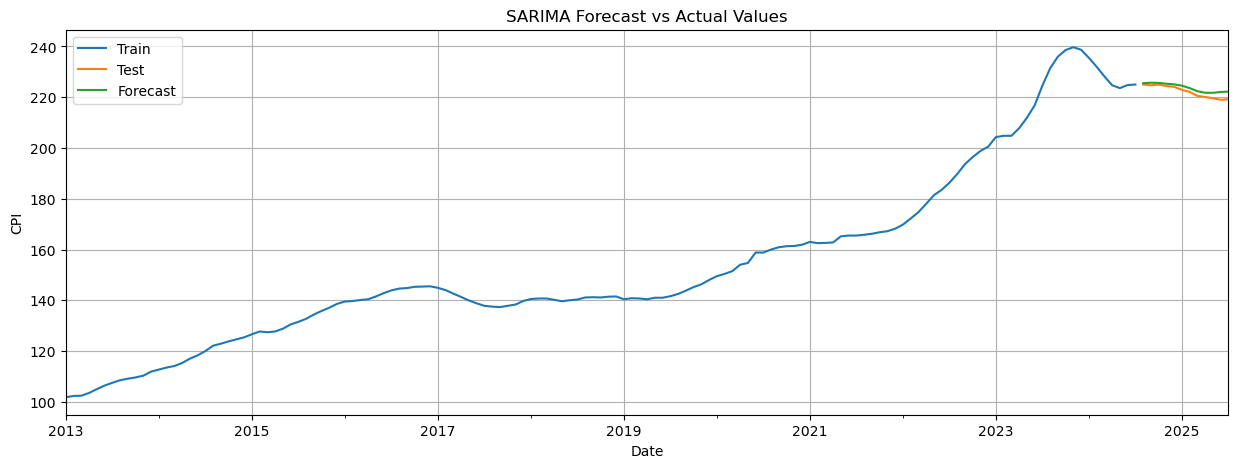

In [40]:
sarima_forecast = results.forecast(steps=test_size)

plt.figure(figsize=(15, 5))

train.plot(label='Train')
test.plot(label='Test')

sarima_forecast.index = test.index
sarima_forecast.plot(label='Forecast')

plt.title('SARIMA Forecast vs Actual Values')
plt.xlabel('Date')
plt.ylabel('CPI')
plt.legend()
plt.grid(True)

plt.show()

In [41]:
import numpy as np
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(test, sarima_forecast)
tmse = np.sqrt(rmse)
tmse

1.7766911922349973

In [42]:
results = model.fit()


import joblib
joblib.dump(results, 'Spices-Urban.pkl')

['Spices-Urban.pkl']